In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# Set plot style for better visualization
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
class WeightedMSELoss(nn.Module):
    """
    A custom weighted Mean Squared Error loss function for traffic forecasting.

    This loss function applies two types of weights to the standard MSE:
    1. Jam-Level Weight: Increases the loss for observations with higher true jam levels.
       This helps the model focus on predicting important high-traffic events in an
       unbalanced dataset. The weight is calculated as (1 + alpha * y_true).
    2. Time-Step Weight: Increases the loss for predictions further in the future.
       This encourages the model to maintain accuracy over a long forecast horizon.
       The weight is calculated as (1 + beta * t) for a linear increase.
    """
    def __init__(self, alpha: float = 1.0, beta: float = 0.05):
        """
        Initializes the WeightedMSELoss.

        Args:
            alpha (float): Hyperparameter to control the jam-level weighting.
                           Higher values penalize errors on high-jam instances more.
            beta (float): Hyperparameter to control the time-step weighting.
                          Higher values penalize errors on distant future predictions more.
        """
        super().__init__()
        self.alpha = alpha
        self.beta = beta

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        """
        Computes the weighted MSE loss.

        Args:
            y_pred (torch.Tensor): The model's predictions. Shape: [B, N, T].
            y_true (torch.Tensor): The ground truth values. Shape: [B, N, T].

        Returns:
            torch.Tensor: The final computed loss value.
        """
        assert y_pred.shape == y_true.shape, "Prediction and ground truth must have the same shape"

        squared_error = torch.pow(y_pred - y_true, 2)

        # These weights are based on the ground truth values
        jam_weights = 1 + self.alpha * y_true
        time_steps = torch.arange(y_true.shape[2], device=y_true.device, dtype=y_true.dtype)
        time_weights = 1 + self.beta * time_steps

        # Reshape time_weights for broadcasting to [1, 1, T]
        time_weights = time_weights.view(1, 1, -1)

        # Apply both weights to the squared error
        weighted_squared_error = jam_weights * time_weights * squared_error

        loss = torch.mean(weighted_squared_error)
        return loss

In [ ]:
# Instantiate a standard MSE loss for comparison
mse_loss_fn = nn.MSELoss()

## Test 1: Weight of jam level (fixed time)

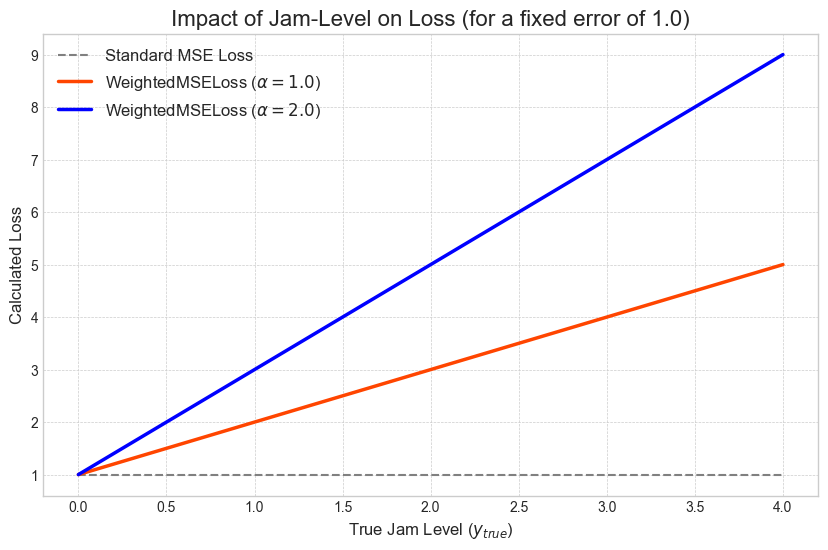

In [10]:
weighted_loss_fn_alpha_1 = WeightedMSELoss(alpha=1.0, beta=0.1)
weighted_loss_fn_alpha_2 = WeightedMSELoss(alpha=2.0, beta=0.1)

true_jams = torch.linspace(0, 4, 100)
# Introduce a fixed error of +1.0
pred_jams = true_jams + 1.0

# Reshape for loss function (B=1, N=1, T=1)
true_jams_reshaped = true_jams.view(1, 1, -1)
pred_jams_reshaped = pred_jams.view(1, 1, -1)

# Calculate loss for each point
weighted_losses_jam_1 = []
weighted_losses_jam_2 = []
mse_losses_jam = []

for i in range(len(true_jams)):
    # We pass single values with the correct shape
    w_loss_1 = weighted_loss_fn_alpha_1(pred_jams_reshaped[:,:,i:i+1], true_jams_reshaped[:,:,i:i+1])
    w_loss_2 = weighted_loss_fn_alpha_2(pred_jams_reshaped[:,:,i:i+1], true_jams_reshaped[:,:,i:i+1])
    m_loss = mse_loss_fn(pred_jams_reshaped[:,:,i:i+1], true_jams_reshaped[:,:,i:i+1])

    weighted_losses_jam_1.append(w_loss_1.item())
    weighted_losses_jam_2.append(w_loss_2.item())
    mse_losses_jam.append(m_loss.item())
    
# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(true_jams.numpy(), mse_losses_jam, label='Standard MSE Loss', linestyle='--', color='gray')
plt.plot(true_jams.numpy(), weighted_losses_jam_1, label=f'WeightedMSELoss ($\\alpha = {weighted_loss_fn_alpha_1.alpha}$)', color='orangered', linewidth=2.5)
plt.plot(true_jams.numpy(), weighted_losses_jam_2, label=f'WeightedMSELoss ($\\alpha = {weighted_loss_fn_alpha_2.alpha}$)', color='blue', linewidth=2.5)

plt.title('Impact of Jam-Level on Loss (for a fixed error of 1.0)', fontsize=16)
plt.xlabel('True Jam Level ($y_{true}$)', fontsize=12)
plt.ylabel('Calculated Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

### Observations

- The Standard MSE loss is constant because the squared error $(1.0)^2 = 1.0$ is the same regardless of the true jam level.
- The `WeightedMSELoss` increases linearly with the true jam level. An error on a road with `jam_level==4` contributes significantly more to the total loss than the same error on a road with `jam_level=0`.

## Test 2: Weight of time (fixed jam level)

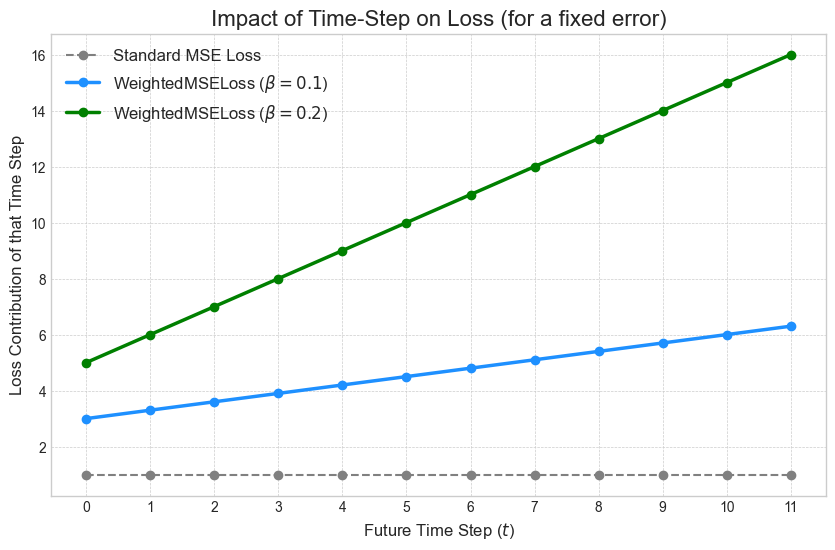

In [8]:
T = 12
time_steps = np.arange(T)

weighted_loss_fn_beta_1 = WeightedMSELoss(alpha=1.0, beta=0.1)
weighted_loss_fn_beta_2 = WeightedMSELoss(alpha=2.0, beta=0.2)

# Fixed true value and prediction
y_true_val = 2.0
y_pred_val = 3.0

weighted_losses_time = []
mse_losses_time = []

# We create tensors of shape [1,1,T] and compute the overall loss,
# then show how each component contributes
y_true_series = torch.full((1, 1, T), y_true_val)
y_pred_series = torch.full((1, 1, T), y_pred_val)

# To see the loss contribution of each timestep, we calculate it manually
base_error_sq = (y_pred_val - y_true_val)**2 # This is 1.0
w_loss_components_1 = base_error_sq * (1 + weighted_loss_fn_beta_1.alpha * y_true_val) * (1 + weighted_loss_fn_beta_1.beta * time_steps)
w_loss_components_2 = base_error_sq * (1 + weighted_loss_fn_beta_2.alpha * y_true_val) * (1 + weighted_loss_fn_beta_2.beta * time_steps)
m_loss_components = np.full(T, base_error_sq)


# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(time_steps, m_loss_components, label='Standard MSE Loss', linestyle='--', color='gray', marker='o')
plt.plot(time_steps, w_loss_components_1, label=f'WeightedMSELoss ($\\beta = {weighted_loss_fn_beta_1.beta}$)', color='dodgerblue', linewidth=2.5, marker='o')
plt.plot(time_steps, w_loss_components_2, label=f'WeightedMSELoss ($\\beta = {weighted_loss_fn_beta_2.beta}$)', color='green', linewidth=2.5, marker='o')

plt.title('Impact of Time-Step on Loss (for a fixed error)', fontsize=16)
plt.xlabel('Future Time Step ($t$)', fontsize=12)
plt.ylabel('Loss Contribution of that Time Step', fontsize=12)
plt.xticks(time_steps)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

### Observations

- With Standard MSE, the loss contributed by each time step is identical, as the error is the same.
- With WeightedMSELoss, the loss contribution grows linearly for each step into the future. An error at $t=11$ is penalized much more than the same error at $t=0$, pushing the model to learn long-term dependencies.

## Test 3: Combined Penalization

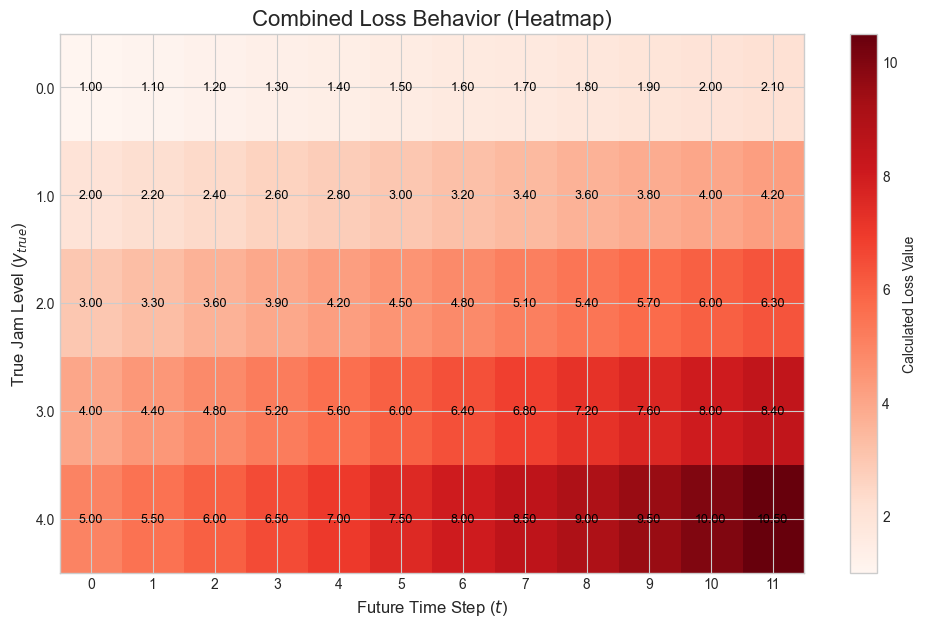

In [9]:
weighted_loss_fn = WeightedMSELoss(alpha=1.0, beta=0.1)

T = 12
time_steps_grid = np.arange(T)
true_jams_grid = np.linspace(0, 4, 5) # Test at jam levels 0, 1, 2, 3, 4

loss_matrix = np.zeros((len(true_jams_grid), T))

# Fixed error of +1.0
error_sq = 1.0

for i, jam in enumerate(true_jams_grid):
    for j, t in enumerate(time_steps_grid):
        jam_weight = 1 + weighted_loss_fn.alpha * jam
        time_weight = 1 + weighted_loss_fn.beta * t
        loss_matrix[i, j] = error_sq * jam_weight * time_weight

fig, ax = plt.subplots(figsize=(12, 7))
cax = ax.imshow(loss_matrix, cmap='Reds', aspect='auto')

ax.set_xticks(np.arange(T))
ax.set_xticklabels(time_steps_grid)
ax.set_yticks(np.arange(len(true_jams_grid)))
ax.set_yticklabels([f"{j:.1f}" for j in true_jams_grid])

plt.title('Combined Loss Behavior (Heatmap)', fontsize=16)
plt.xlabel('Future Time Step ($t$)', fontsize=12)
plt.ylabel('True Jam Level ($y_{true}$)', fontsize=12)
fig.colorbar(cax, label='Calculated Loss Value')

# Add text annotations
for i in range(len(true_jams_grid)):
    for j in range(T):
        ax.text(j, i, f'{loss_matrix[i, j]:.2f}', ha='center', va='center', color='black', fontsize=9)
        
plt.show()

### Observations

- The heatmap clearly shows the combined effect. The loss is 
    - lowest at the bottom-left (low jam, near-term forecast), and 
    - highest at the top-right (high jam, long-term forecast).
- This visualization confirms that the loss function is correctly prioritizing the two conditions we wanted to specify.